In [26]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

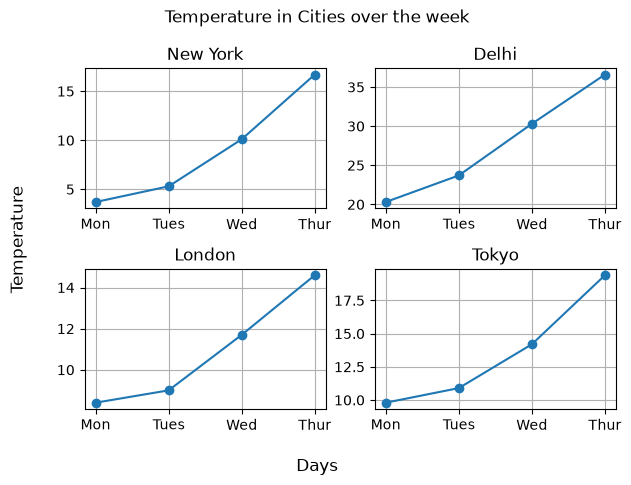

In [7]:
# Task
days = [
  "Mon",
  "Tues",
  "Wed",
  "Thur",
]

cities = [
  "New York",
  "Delhi",
  "London",
  "Tokyo"
]

temperature = [
  [
    3.7, 5.3, 10.1, 16.7
  ],
  [
    20.3, 23.7, 30.3, 36.6
  ],
  [
    8.4, 9.0, 11.7, 14.6
  ],
  [
    9.8, 10.9, 14.2, 19.4
  ]
]

fig, axes = plt.subplots(2, 2)
city_no = 0

for i in range(2): # rows
    for j in range(2): # cols
        axes[i][j].plot(days, temperature[city_no], marker='o')
        axes[i][j].set_title(cities[city_no])
        axes[i][j].grid()
        city_no = city_no + 1

fig.suptitle("Temperature in Cities over the week")
fig.supylabel("Temperature")
fig.supxlabel("Days")
fig.tight_layout()

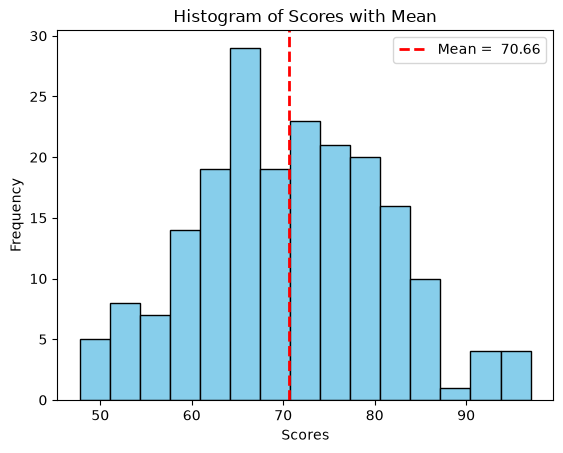

In [47]:
# For the following datasets genrate the histogram of scores, draw the vertical line of mean and try to intercept the result
scores = np.random.normal(loc=70, scale=10, size=200)

mean_score = np.mean(scores)

plt.hist(scores, bins=15, edgecolor='black', color='skyblue')
plt.axvline(mean_score, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_score: .2f}')

plt.xlabel('Scores')
plt.ylabel('Frequency')
plt.title('Histogram of Scores with Mean')
plt.legend()

plt.show()

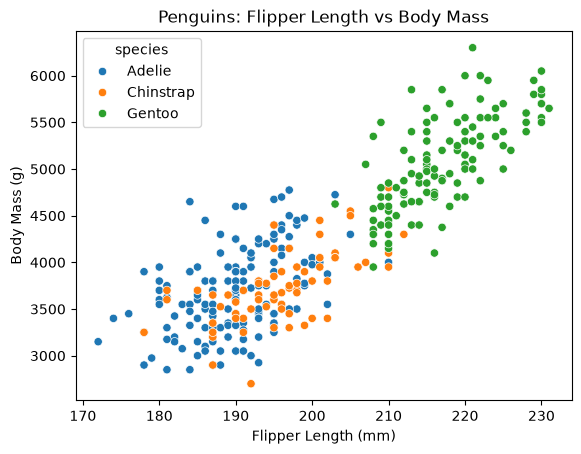

In [44]:
penguins = sns.load_dataset("penguins")

sns.scatterplot(
    data = penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

plt.title("Penguins: Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.show()

     total_bill   tip     sex smoker   day    time  size
0         16.99  1.01  Female     No   Sun  Dinner     2
1         10.34  1.66    Male     No   Sun  Dinner     3
2         21.01  3.50    Male     No   Sun  Dinner     3
3         23.68  3.31    Male     No   Sun  Dinner     2
4         24.59  3.61  Female     No   Sun  Dinner     4
..          ...   ...     ...    ...   ...     ...   ...
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2

[244 rows x 7 columns]


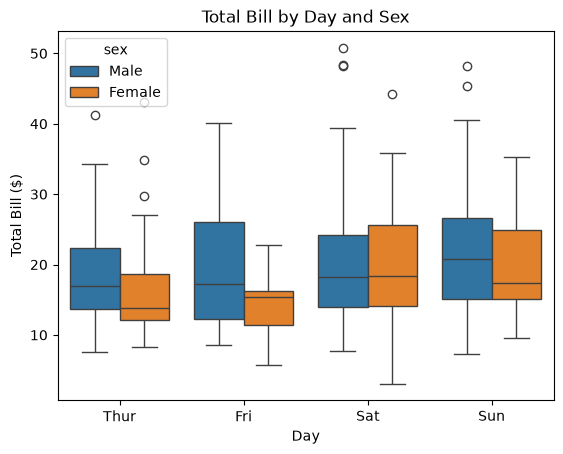

day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64


In [50]:
tips = sns.load_dataset("tips")

sns.boxplot(
    data = tips,
    x="day",
    y="total_bill",
    hue="sex"
)

plt.title("Total Bill by Day and Sex")
plt.xlabel("Day")
plt.ylabel("Total Bill ($)")
plt.show()

print(tips.groupby("day", observed=False)["total_bill"].median())

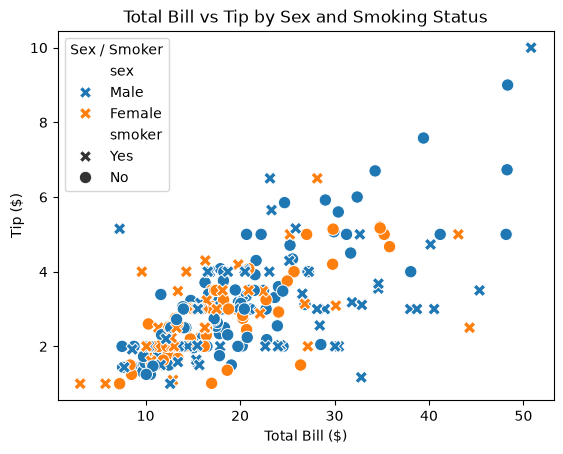

smoker
Yes    3.008710
No     2.991854
Name: tip, dtype: float64


In [57]:
# Create scatter plot
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="sex",
    style="smoker",
    markers={"Yes": "X", "No": "o"},
    s=80
)

plt.title("Total Bill vs Tip by Sex and Smoking Status")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.legend(title="Sex / Smoker")
plt.show()

print(tips.groupby("smoker", observed=False)["tip"].mean())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
time  Lunch  Dinner
day                
Thur   2.77    3.00
Fri    2.38    2.94
Sat     NaN    2.99
Sun     NaN    3.26


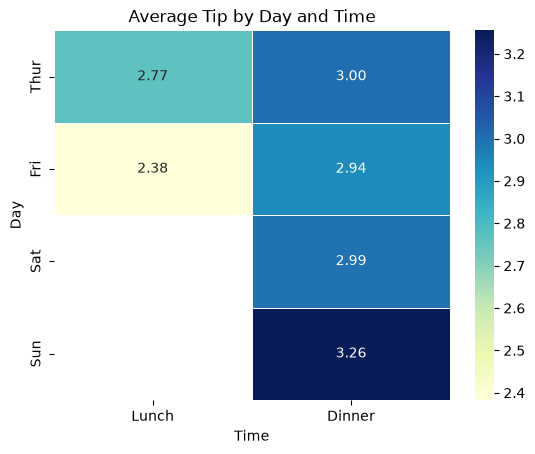

Highest average tip: ('Sun', 'Dinner')
Average tip amount: 3.26


In [68]:
tips = sns.load_dataset("tips")
print(tips.head())

pivot_table = tips.pivot_table(
    values="tip",
    index="day",
    columns="time",
    observed=False,
    aggfunc="mean"
)

print(pivot_table.round(2))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Tip by Day and Time")
plt.xlabel("Time")
plt.ylabel("Day")
plt.show()

best = pivot_table.stack().idxmax()
highest_tip = pivot_table.stack().max()

print("Highest average tip:", best)
print("Average tip amount:", round(highest_tip, 2))